In [ ]:
!pip install tensorflow
!pip install nltk

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.preprocessing.image import load_img
from tensorflow.keras.preprocessing.image import img_to_array
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.models import Model

import string

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
captions_path = "/content/drive/MyDrive/Flickr8k/captions.txt"

captions = pd.read_csv(captions_path)

captions.head()

,image,caption
0,1000268201_693b08cb0e.jpg,A child in a pink dress is climbing up a set o...
1,1000268201_693b08cb0e.jpg,A girl going into a wooden building .
2,1000268201_693b08cb0e.jpg,A little girl climbing into a wooden playhouse .
3,1000268201_693b08cb0e.jpg,A little girl climbing the stairs to her playh...
4,1000268201_693b08cb0e.jpg,A little girl in a pink dress going into a woo...


In [ ]:
print("Shape :", captions.shape)

print(captions.head())

print(captions.describe())

Shape : (40455, 2)
                       image  \
0  1000268201_693b08cb0e.jpg   
1  1000268201_693b08cb0e.jpg   
2  1000268201_693b08cb0e.jpg   
3  1000268201_693b08cb0e.jpg   
4  1000268201_693b08cb0e.jpg   

                                             caption  
0  A child in a pink dress is climbing up a set o...  
1              A girl going into a wooden building .  
2   A little girl climbing into a wooden playhouse .  
3  A little girl climbing the stairs to her playh...  
4  A little girl in a pink dress going into a woo...  
                           image                         caption
count                      40455                           40455
unique                      8091                           40201
top     997722733_0cb5439472.jpg  Two dogs playing in the snow .
freq                           5                               7


In [ ]:
captions.isnull().sum()

,0
image,0
caption,0


In [ ]:
def clean_caption(text):

    text = text.lower()

    text = text.translate(str.maketrans('', '', string.punctuation))

    text = "startseq " + text + " endseq"

    return text

captions['caption'] = captions['caption'].apply(clean_caption)

captions.head()

,image,caption
0,1000268201_693b08cb0e.jpg,startseq a child in a pink dress is climbing u...
1,1000268201_693b08cb0e.jpg,startseq a girl going into a wooden building ...
2,1000268201_693b08cb0e.jpg,startseq a little girl climbing into a wooden ...
3,1000268201_693b08cb0e.jpg,startseq a little girl climbing the stairs to ...
4,1000268201_693b08cb0e.jpg,startseq a little girl in a pink dress going i...


In [ ]:
all_captions = captions['caption'].tolist()

tokenizer = Tokenizer()

tokenizer.fit_on_texts(all_captions)

vocab_size = len(tokenizer.word_index)+1

print(vocab_size)

8831


In [ ]:
max_length = max(len(caption.split()) for caption in all_captions)

print(max_length)

38


In [ ]:
model = VGG16()

model = Model(inputs=model.inputs,
              outputs=model.layers[-2].output)

print(model.summary())

553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 134,260,544 (512.16 MB)

 Trainable params: 134,260,544 (512.16 MB)

 Non-trainable params: 0 (0.00 B)

None


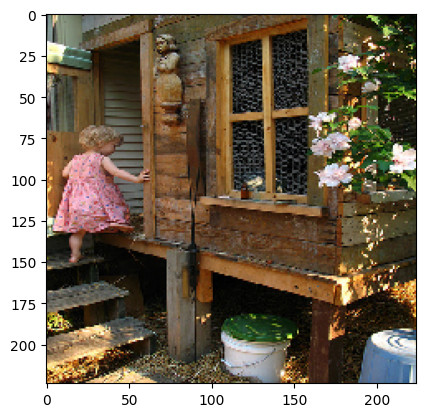

In [ ]:
image_path="/content/drive/MyDrive/Flickr8k/Images/1000268201_693b08cb0e.jpg"

image=load_img(image_path,target_size=(224,224))

plt.imshow(image)

plt.show()

In [ ]:
image=img_to_array(image)

image=np.expand_dims(image,axis=0)

image=preprocess_input(image)

feature=model.predict(image)

print(feature.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
(1, 4096)


In [ ]:
from sklearn.model_selection import train_test_split

images = captions['image'].unique()

train, test = train_test_split(images,
                               test_size=0.2,
                               random_state=42)

print("Training Images:", len(train))

print("Testing Images:", len(test))

Training Images: 6472
Testing Images: 1619


In [ ]:
# Select first 500 unique images
selected_images = images[:500]

# Keep captions only for these images
captions_500 = captions[captions['image'].isin(selected_images)]

print("Number of images:", len(selected_images))
print("Number of captions:", len(captions_500))

Number of images: 500
Number of captions: 2500


In [ ]:
features = {}

images_path = "/content/drive/MyDrive/Flickr8k/Images"

for image_name in selected_images:

    img_path = os.path.join(images_path, image_name)

    image = load_img(img_path, target_size=(224,224))

    image = img_to_array(image)

    image = np.expand_dims(image, axis=0)

    image = preprocess_input(image)

    feature = model.predict(image, verbose=0)

    features[image_name] = feature

print("Extracted features:", len(features))

Extracted features: 500


In [ ]:
import pickle

pickle.dump(features,
            open("/content/drive/MyDrive/Flickr8k/features500.pkl","wb"))

In [ ]:
mapping = {}

for row in captions_500.itertuples():

    image = row.image

    caption = row.caption

    if image not in mapping:
        mapping[image] = []

    mapping[image].append(caption)

print("Images in mapping:", len(mapping))

Images in mapping: 500


In [ ]:
from tensorflow.keras.utils import to_categorical

def data_generator(mapping,
                   features,
                   tokenizer,
                   max_length,
                   vocab_size):

    while True:

        for image, captions in mapping.items():

            feature = features[image][0]

            for caption in captions:

                seq = tokenizer.texts_to_sequences([caption])[0]

                for i in range(1, len(seq)):

                    in_seq = seq[:i]

                    out_seq = seq[i]

                    in_seq = pad_sequences([in_seq],
                                           maxlen=max_length)[0]

                    out_seq = to_categorical(out_seq,
                                             num_classes=vocab_size)

                    yield ([feature, in_seq], out_seq)

In [ ]:
from tensorflow.keras.layers import Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Embedding
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import add

# Image branch
inputs1 = Input(shape=(4096,))
fe1 = Dropout(0.5)(inputs1)
fe2 = Dense(256, activation='relu')(fe1)

# Caption branch
inputs2 = Input(shape=(max_length,))
se1 = Embedding(vocab_size, 256, mask_zero=True)(inputs2)
se2 = Dropout(0.5)(se1)
se3 = LSTM(256)(se2)

# Merge
decoder1 = add([fe2, se3])
decoder2 = Dense(256, activation='relu')(decoder1)
outputs = Dense(vocab_size, activation='softmax')(decoder2)

model = Model(inputs=[inputs1, inputs2],
              outputs=outputs)

model.compile(loss='categorical_crossentropy',
              optimizer='adam')

print(model.summary())

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 38)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 4096)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 38, 256)   │  2,260,736 │ input_layer_2[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 4096)      │          0 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 38, 256)   │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 38)        │          0 │ input_layer_2[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │  1,048,832 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 256)       │    525,312 │ dropout_1[0][0],  │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 256)       │          0 │ dense[0][0],      │
│                     │                   │            │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 256)       │     65,792 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 8831)      │  2,269,567 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,170,239 (23.54 MB)

 Trainable params: 6,170,239 (23.54 MB)

 Non-trainable params: 0 (0.00 B)

None


In [ ]:
from tensorflow.keras.utils import to_categorical

X1 = []
X2 = []
y = []

for image, captions_list in mapping.items():

    feature = features[image][0]

    for caption in captions_list:

        seq = tokenizer.texts_to_sequences([caption])[0]

        for i in range(1, len(seq)):

            in_seq = seq[:i]
            out_seq = seq[i]

            in_seq = pad_sequences([in_seq],
                                   maxlen=max_length)[0]

            out_seq = to_categorical(out_seq,
                                     num_classes=vocab_size)

            X1.append(feature)
            X2.append(in_seq)
            y.append(out_seq)

X1 = np.array(X1)
X2 = np.array(X2)
y = np.array(y)

print(X1.shape)
print(X2.shape)
print(y.shape)

(30165, 4096)
(30165, 38)
(30165, 8831)


In [ ]:
model.fit(
    [X1, X2],
    y,
    epochs=10,
    batch_size=64,
    verbose=1
)

Epoch 1/10
472/472 ━━━━━━━━━━━━━━━━━━━━ 240s 485ms/step - loss: 5.0515
Epoch 2/10
472/472 ━━━━━━━━━━━━━━━━━━━━ 245s 451ms/step - loss: 3.9290
Epoch 3/10
472/472 ━━━━━━━━━━━━━━━━━━━━ 261s 450ms/step - loss: 3.3593
Epoch 4/10
472/472 ━━━━━━━━━━━━━━━━━━━━ 223s 473ms/step - loss: 2.9449
Epoch 5/10
472/472 ━━━━━━━━━━━━━━━━━━━━ 222s 471ms/step - loss: 2.6339
Epoch 6/10
472/472 ━━━━━━━━━━━━━━━━━━━━ 209s 442ms/step - loss: 2.3904
Epoch 7/10
472/472 ━━━━━━━━━━━━━━━━━━━━ 261s 440ms/step - loss: 2.1953
Epoch 8/10
472/472 ━━━━━━━━━━━━━━━━━━━━ 210s 444ms/step - loss: 2.0426
Epoch 9/10
472/472 ━━━━━━━━━━━━━━━━━━━━ 256s 433ms/step - loss: 1.9131
Epoch 10/10
472/472 ━━━━━━━━━━━━━━━━━━━━ 270s 450ms/step - loss: 1.8025


In [ ]:
model.save("/content/drive/MyDrive/Flickr8k/image_caption_model.h5")

In [ ]:
def predict_caption(model, feature, tokenizer, max_length):

    caption = "startseq"

    for i in range(max_length):

        sequence = tokenizer.texts_to_sequences([caption])[0]

        sequence = pad_sequences([sequence], maxlen=max_length)

        prediction = model.predict([feature, sequence], verbose=0)

        predicted_id = np.argmax(prediction)

        word = tokenizer.index_word.get(predicted_id)

        if word is None:
            break

        caption += " " + word

        if word == "endseq":
            break

    caption = caption.replace("startseq", "")
    caption = caption.replace("endseq", "")

    return caption.strip()

In [ ]:
test_image = selected_images[0]

feature = features[test_image]

print("Image:", test_image)

print("Caption:")

print(predict_caption(model,
                      feature,
                      tokenizer,
                      max_length))

Image: 1000268201_693b08cb0e.jpg
Caption:
a girl in a pink dress and pink dress and a pink dress and a girl in a dress


In [ ]:
model.save("/content/drive/MyDrive/Flickr8k/image_caption_model.keras")

print("Model Saved Successfully!")

Model Saved Successfully!


In [ ]:
# Reverse mapping of word IDs to words
index_word = tokenizer.index_word

In [ ]:
import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences

def predict_caption(model, image_feature, tokenizer, max_length):

    in_text = "startseq"

    for i in range(max_length):

        sequence = tokenizer.texts_to_sequences([in_text])[0]

        sequence = pad_sequences([sequence], maxlen=max_length)

        yhat = model.predict([image_feature, sequence], verbose=0)

        yhat = np.argmax(yhat)

        word = index_word.get(yhat)

        if word is None:
            break

        in_text += " " + word

        if word == "endseq":
            break

    final_caption = in_text.replace("startseq", "")
    final_caption = final_caption.replace("endseq", "")

    return final_caption.strip()

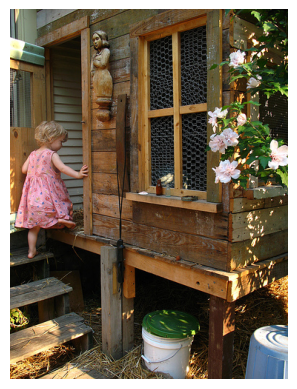

In [ ]:
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img

test_image = selected_images[0]

img_path = os.path.join(images_path, test_image)

img = load_img(img_path)

plt.imshow(img)
plt.axis("off")
plt.show()

In [ ]:
feature = features[test_image]

caption = predict_caption(
    model,
    feature,
    tokenizer,
    max_length
)

print("Generated Caption:")
print(caption)

Generated Caption:
a girl in a pink dress and pink dress and a pink dress and a girl in a dress


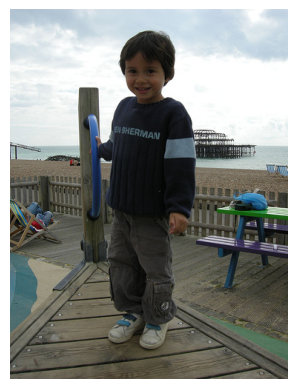

Generated Caption:
a young boy in a red shirt and black standing on a railing near the background


In [ ]:
import random

test_image = random.choice(selected_images)

img_path = os.path.join(images_path, test_image)

img = load_img(img_path)

plt.imshow(img)
plt.axis("off")
plt.show()

feature = features[test_image]

caption = predict_caption(
    model,
    feature,
    tokenizer,
    max_length
)

print("Generated Caption:")
print(caption)

In [ ]:
from nltk.translate.bleu_score import sentence_bleu

actual = mapping[test_image][0].split()

predicted = caption.split()

score = sentence_bleu([actual], predicted)

print("BLEU Score:", score)

BLEU Score: 3.4351746675165266e-78


/usr/local/lib/python3.12/dist-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)


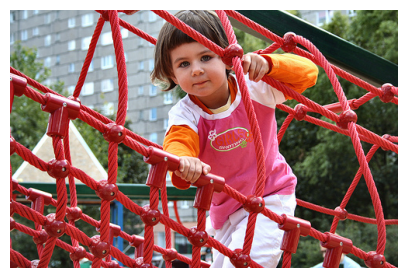

NameError: name 'generate_caption' is not defined

In [ ]:
for i in range(5):

    image = random.choice(selected_images)

    plt.figure(figsize=(5,5))

    img = load_img(os.path.join(images_path, image))

    plt.imshow(img)

    plt.axis("off")

    plt.show()

    feature = features[image]

    caption = generate_caption(
        model,
        feature,
        tokenizer,
        max_length
    )

    print("Predicted Caption:")
    print(caption)
    print("-"*50)

In [ ]:
import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences

def generate_caption(model, feature, tokenizer, max_length):

    in_text = "startseq"

    for i in range(max_length):

        sequence = tokenizer.texts_to_sequences([in_text])[0]
        sequence = pad_sequences([sequence], maxlen=max_length)

        prediction = model.predict([feature, sequence], verbose=0)

        prediction = np.argmax(prediction)

        word = tokenizer.index_word.get(prediction)

        if word is None:
            break

        in_text += " " + word

        if word == "endseq":
            break

    return in_text.replace("startseq", "").replace("endseq", "").strip()

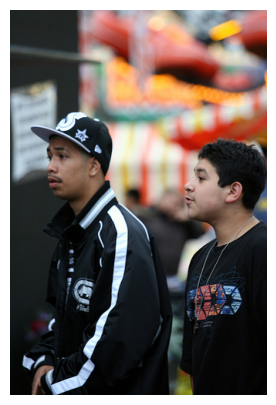

Predicted Caption:
two men dressed in a city
--------------------------------------------------


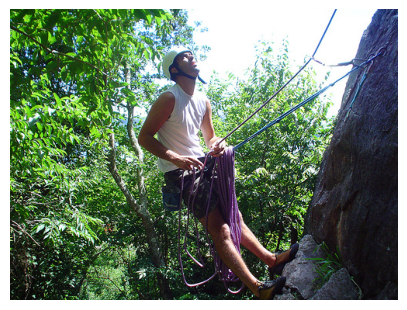

Predicted Caption:
a man in a white shirt and helmet is climbing a rock
--------------------------------------------------


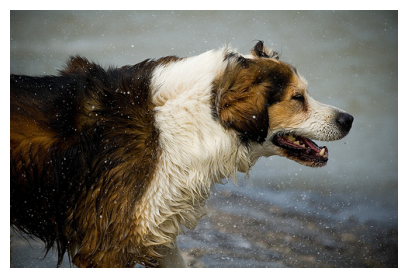

Predicted Caption:
a furry dog shakes a self dry
--------------------------------------------------


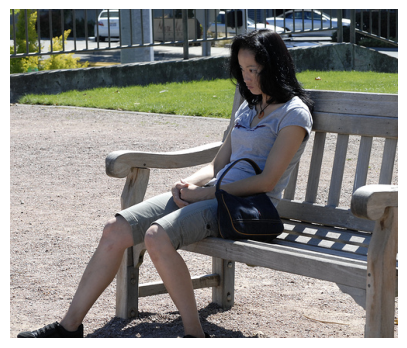

Predicted Caption:
a woman with a handbag and a black and black purse sitting on a wooden bench
--------------------------------------------------


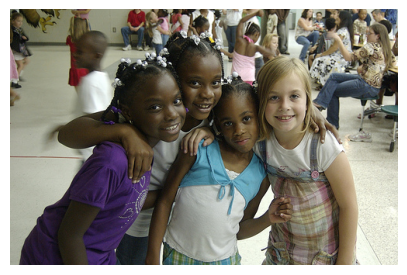

Predicted Caption:
a group of girls in a flower stand in a crowd
--------------------------------------------------


In [ ]:
for i in range(5):

    image = random.choice(selected_images)

    plt.figure(figsize=(5,5))

    img = load_img(os.path.join(images_path, image))

    plt.imshow(img)

    plt.axis("off")

    plt.show()

    feature = features[image]

    caption = generate_caption(
        model,
        feature,
        tokenizer,
        max_length
    )

    print("Predicted Caption:")
    print(caption)
    print("-"*50)

In [ ]:
!pip install gTTS

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 4.7 MB/s eta 0:00:00
  Attempting uninstall: click
    Found existing installation: click 8.4.2
    Uninstalling click-8.4.2:
      Successfully uninstalled click-8.4.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
huggingface-hub 1.23.0 requires click<9.0.0,>=8.4.2, but you have click 8.1.8 which is incompatible.
wandb 0.28.0 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.


In [ ]:
from gtts import gTTS
from IPython.display import Audio

caption = generate_caption(model, feature, tokenizer, max_length)

print("Generated Caption:", caption)

tts = gTTS(text=caption, lang='en')

tts.save("caption.mp3")

Audio("caption.mp3", autoplay=True)

Generated Caption: a group of girls in a flower stand in a crowd


In [ ]:
from gtts import gTTS
from IPython.display import Audio

caption = generate_caption(model, feature, tokenizer, max_length)

print("Generated Caption:", caption)

tts = gTTS(text=caption, lang="en")
tts.save("caption.mp3")

Audio("caption.mp3", autoplay=True)

Generated Caption: a group of girls in a flower stand in a crowd
